# 03 - Loan default classification (SYNTHETIC data)
**Target:** `is_default` = loan is 90+ DPD at the snapshot date, for loans with >= 15 months on book (outcome observable).
**Prediction point:** loan origination. Features = customer attributes, application-time financial profile, loan terms. Nothing from repayments/collections.
**Split:** *out-of-time* - train on loans disbursed up to 2024-09-30, test on later disbursements. A random split would let the model "see the future" of the same period.
**Leakage controls:** preprocessing is fitted inside a Pipeline on training data only; the threshold is chosen using cross-validated predictions on the training set only.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

from src.data_access import load_tables
from src.analytics.common import setup, save_fig, save_results, banner
from src.modelling import features as F

setup(); banner()
SEED = 42
t = load_tables()
data = F.default_dataset(t)
train, test = F.temporal_split(data, F.TRAIN_END_DEFAULT)
assert not (set(F.FEATURES) & set(F.FORBIDDEN_FEATURES)), "forbidden feature in feature list"
Xtr, ytr, Xte, yte = train[F.FEATURES], train.is_default, test[F.FEATURES], test.is_default
print(f"train: {len(train)} loans ({train.disbursement_date.min().date()}..{train.disbursement_date.max().date()}), default rate {ytr.mean():.2%}")
print(f"test : {len(test)} loans ({test.disbursement_date.min().date()}..{test.disbursement_date.max().date()}), default rate {yte.mean():.2%}")
res = dict(train=dict(n=len(train), default_rate=float(ytr.mean())), test=dict(n=len(test), default_rate=float(yte.mean())))

ALL DATA IN THIS PROJECT IS SYNTHETIC. Findings describe the simulation, not real lending.


[data] loaded from PostgreSQL (analytics schema)
train: 6508 loans (2023-07-01..2024-09-30), default rate 8.45%
test : 3856 loans (2024-10-01..2025-03-30), default rate 8.84%


## Models compared
1. **Dummy (prior)** - always predicts the training default rate; AUC = 0.5. The floor any model must beat.
2. **Logistic regression** (scaled, class-weighted) - interpretable baseline.
3. **Random forest** - non-linear, bagged trees.
4. **Gradient boosting** (HistGradientBoosting) - usually strongest on tabular data.
Class imbalance (~9% defaults) is handled with `class_weight='balanced'` where available. **ROC-AUC** and **PR-AUC** are threshold-free;
precision / recall / F1 / confusion matrix need a threshold, chosen on training data (max F1 over cross-validated predictions) and then applied unchanged to the test set.

In [2]:
models = {
    "Dummy (prior)": Pipeline([("pre", F.make_preprocessor(False)), ("m", DummyClassifier(strategy="prior"))]),
    "Logistic regression": Pipeline([("pre", F.make_preprocessor(True)), ("m", LogisticRegression(max_iter=2000, class_weight="balanced", C=0.5))]),
    "Random forest": Pipeline([("pre", F.make_preprocessor(False)), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=20, class_weight="balanced_subsample",
                                                                                                 n_jobs=-1, random_state=SEED))]),
    "Gradient boosting": Pipeline([("pre", F.make_preprocessor(False)), ("m", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=200, max_leaf_nodes=8,
                                                                                                             min_samples_leaf=40, l2_regularization=1.0,
                                                                                                             class_weight="balanced", random_state=SEED))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows, fitted, probs = [], {}, {}
for name, pipe in models.items():
    cv_p = cross_val_predict(clone(pipe), Xtr, ytr, cv=cv, method="predict_proba")[:, 1]
    cands = np.linspace(0.05, 0.95, 91)
    thr = float(cands[np.argmax([f1_score(ytr, cv_p >= c) for c in cands])]) if name != "Dummy (prior)" else 0.5
    pipe.fit(Xtr, ytr)
    p = pipe.predict_proba(Xte)[:, 1]
    pred = (p >= thr).astype(int)
    fitted[name], probs[name] = pipe, p
    rows.append(dict(model=name, threshold=thr, roc_auc_test=roc_auc_score(yte, p), roc_auc_train_cv=roc_auc_score(ytr, cv_p), pr_auc_test=average_precision_score(yte, p),
                     precision=precision_score(yte, pred, zero_division=0), recall=recall_score(yte, pred), f1=f1_score(yte, pred, zero_division=0)))
metrics = pd.DataFrame(rows).set_index("model")
print(metrics.round(3))
res["metrics"] = metrics.round(4).to_dict("index")
res["baseline_prevalence"] = float(yte.mean())

                     threshold  roc_auc_test  roc_auc_train_cv  pr_auc_test  \
model                                                                         
Dummy (prior)             0.50         0.500             0.500        0.088   
Logistic regression       0.76         0.805             0.805        0.394   
Random forest             0.50         0.794             0.801        0.368   
Gradient boosting         0.71         0.787             0.790        0.355   

                     precision  recall     f1  
model                                          
Dummy (prior)            0.000   0.000  0.000  
Logistic regression      0.411   0.384  0.397  
Random forest            0.288   0.499  0.365  
Gradient boosting        0.358   0.367  0.362  


## Confusion matrices and ROC (test set, out-of-time)

Best model on test ROC-AUC: Logistic regression


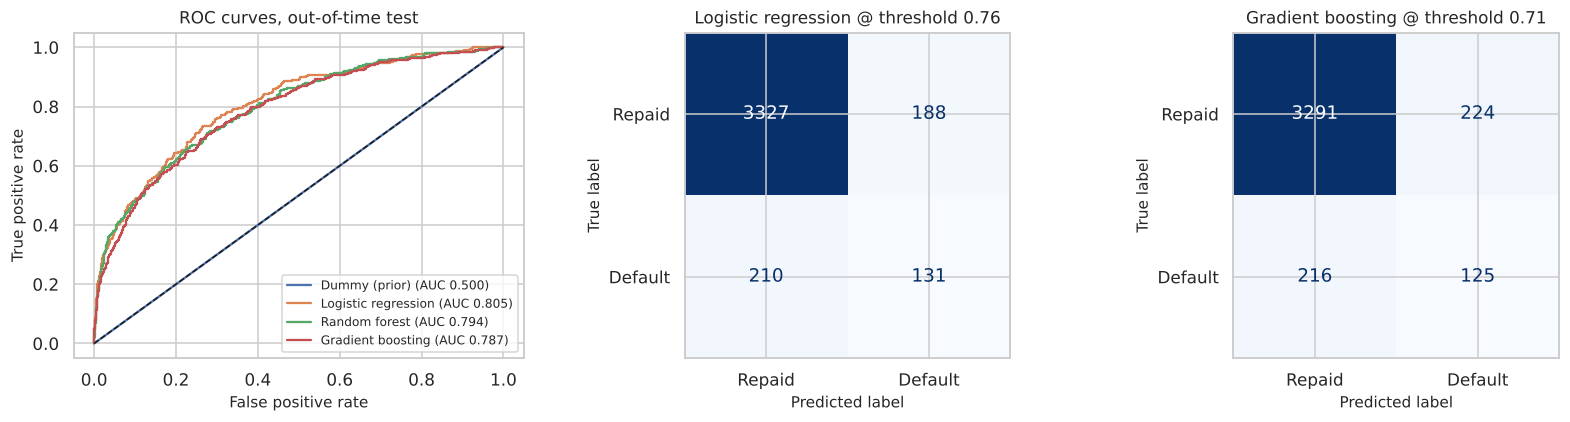

In [3]:
best = metrics.drop("Dummy (prior)").roc_auc_test.idxmax()
print("Best model on test ROC-AUC:", best)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for n_, p in probs.items():
    fpr, tpr, _ = roc_curve(yte, p); axes[0].plot(fpr, tpr, label=f"{n_} (AUC {roc_auc_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].legend(fontsize=8); axes[0].set_title("ROC curves, out-of-time test")
for ax, n_ in zip(axes[1:], ["Logistic regression", best if best != "Logistic regression" else "Gradient boosting"]):
    thr = metrics.loc[n_, "threshold"]; cm = confusion_matrix(yte, probs[n_] >= thr)
    ConfusionMatrixDisplay(cm, display_labels=["Repaid", "Default"]).plot(ax=ax, colorbar=False, cmap="Blues"); ax.set_title(f"{n_} @ threshold {thr:.2f}")
save_fig(fig, "ml_default_roc_confusion")
res["confusion_matrices"] = {n_: confusion_matrix(yte, probs[n_] >= metrics.loc[n_, "threshold"]).tolist() for n_ in probs}
res["best_model"] = best

## Calibration and business use: does a predicted 20% risk mean ~20% default?
Rank-ordering (AUC) is not enough for pricing. We bin test loans by predicted-risk decile and compare average prediction with the observed default rate.
`class_weight='balanced'` inflates probabilities, so calibration of these models is expected to be poor in absolute terms: use them to **rank**, and recalibrate before using as PDs.

        mean_pred  observed_default    n
decile                                  
0           0.052             0.010  386
1           0.104             0.013  386
2           0.152             0.029  385
3           0.204             0.031  386
4           0.261             0.021  385
5           0.327             0.078  386
6           0.406             0.068  385
7           0.514             0.122  386
8           0.645             0.145  385
9           0.837             0.368  386
Top 20% riskiest by score capture 58.1% of all test defaults (random ordering would capture ~20%).


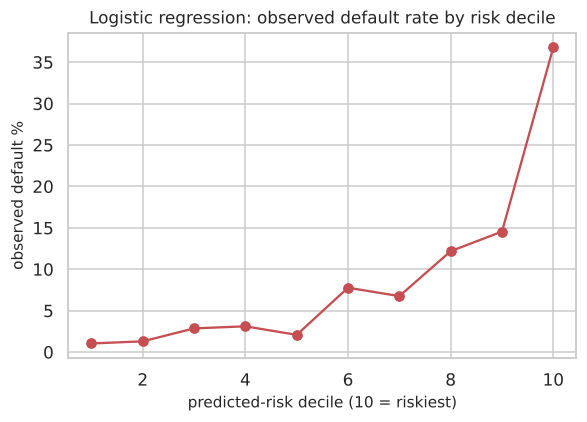

In [4]:
p = probs[best]
dec = pd.qcut(pd.Series(p).rank(method="first"), 10, labels=False)
cal = pd.DataFrame({"decile": dec.values, "pred": p, "obs": yte.values}).groupby("decile").agg(mean_pred=("pred", "mean"), observed_default=("obs", "mean"), n=("obs", "size"))
print(cal.round(3))
res["decile_table"] = cal.round(4).reset_index().to_dict("records")
top20 = cal.tail(2).eval("observed_default * n").sum() / cal.tail(2).n.sum()
cap = yte.values[np.argsort(-p)[: int(0.2 * len(p))]].sum() / yte.sum()
print(f"Top 20% riskiest by score capture {cap:.1%} of all test defaults (random ordering would capture ~20%).")
res["top20pct_capture"] = float(cap)
fig, ax = plt.subplots(figsize=(5.5, 4)); ax.plot(cal.index + 1, cal.observed_default * 100, marker="o", color="#c44e52"); ax.set_xlabel("predicted-risk decile (10 = riskiest)"); ax.set_ylabel("observed default %"); ax.set_title(f"{best}: observed default rate by risk decile")
save_fig(fig, "ml_default_deciles")

## What drives the model? Permutation importance (test set)
Shuffle one feature at a time and measure the AUC drop. **Association, not causation:** e.g. a high-FOIR customer might default because of the burden *or* because
of unobserved factors correlated with FOIR. Importance also gets split across correlated features (interest_rate vs credit_score).

                        importance      sd
credit_score                0.0661  0.0069
foir                        0.0573  0.0050
loan_to_income              0.0223  0.0036
credit_utilization_pct      0.0089  0.0018
acquisition_channel         0.0043  0.0016
previous_loans_count        0.0043  0.0013
city_tier                   0.0034  0.0014
employment_type             0.0033  0.0020
monthly_income              0.0022  0.0010
tenure_months               0.0017  0.0004


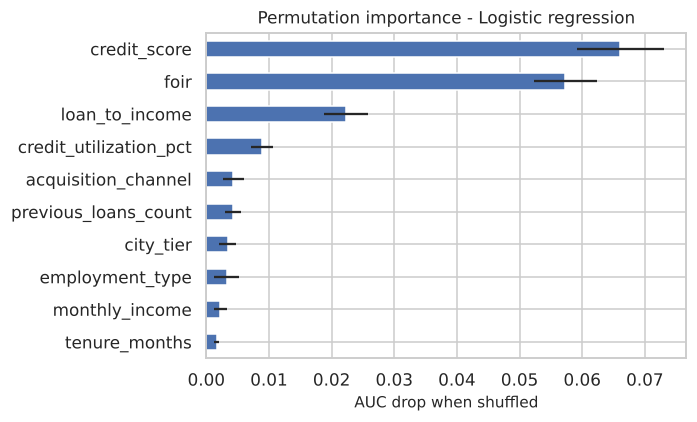

In [5]:
pi = permutation_importance(fitted[best], Xte, yte, scoring="roc_auc", n_repeats=8, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"importance": pi.importances_mean, "sd": pi.importances_std}, index=F.FEATURES).sort_values("importance", ascending=False)
print(imp.head(10).round(4))
res["permutation_importance"] = imp.round(5).head(12).to_dict("index")
fig, ax = plt.subplots(figsize=(6.5, 4)); imp.head(10).iloc[::-1].importance.plot.barh(xerr=imp.head(10).iloc[::-1].sd, ax=ax, color="#4c72b0"); ax.set_xlabel("AUC drop when shuffled"); ax.set_title(f"Permutation importance - {best}")
save_fig(fig, "ml_default_importance")

## Leakage demonstration (what NOT to do)
`current_dpd` and `loan_status` are *outcomes measured after origination*; in fact the target IS `current_dpd >= 90`. Adding `current_dpd` produces a near-perfect model that
would be useless in production, because at the moment of approval it is unknown. Other tempting leaks: `outstanding_balance`, repayment counts, collections outcomes.
A time-aware split also matters: we show the (optimistic) random-split AUC next to the honest out-of-time AUC.

In [6]:
leak_df = data.copy(); leak_df["leaky_current_dpd"] = leak_df.current_dpd
tr_l, te_l = F.temporal_split(leak_df, F.TRAIN_END_DEFAULT)
from sklearn.compose import ColumnTransformer
lk_pre = ColumnTransformer([("keep", "passthrough", ["leaky_current_dpd"])])
lk = Pipeline([("pre", lk_pre), ("m", LogisticRegression(max_iter=1000))]).fit(tr_l[["leaky_current_dpd"]], tr_l.is_default)
leak_auc = roc_auc_score(te_l.is_default, lk.predict_proba(te_l[["leaky_current_dpd"]])[:, 1])
from sklearn.model_selection import train_test_split
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(data[F.FEATURES], data.is_default, test_size=0.3, stratify=data.is_default, random_state=SEED)
rand_auc = roc_auc_score(yr_te, clone(models["Logistic regression"]).fit(Xr_tr, yr_tr).predict_proba(Xr_te)[:, 1])
print(f"LEAKY model (current_dpd as a feature) test AUC: {leak_auc:.3f}   <- looks amazing, unusable")
print(f"Honest logistic regression, random split AUC: {rand_auc:.3f} | out-of-time AUC: {metrics.loc['Logistic regression', 'roc_auc_test']:.3f}")
res["leakage_demo"] = dict(leaky_auc=float(leak_auc), honest_random_split_auc=float(rand_auc), honest_out_of_time_auc=float(metrics.loc["Logistic regression", "roc_auc_test"]))
save_results("ml_default", res)

LEAKY model (current_dpd as a feature) test AUC: 1.000   <- looks amazing, unusable
Honest logistic regression, random split AUC: 0.797 | out-of-time AUC: 0.805
[saved] reports/results/ml_default.json


PosixPath('/home/claude/FinSight/reports/results/ml_default.json')

## Limitations
* **Synthetic data**: the relationships are those we coded into the simulator; real data has noise, selection and drift we did not model. These metrics are *not* performance benchmarks.
* **Selection bias (reject inference)**: we only observe outcomes for customers who were approved and funded.
* **Right-censoring**: restricting to mature loans (>= 15 months) means the newest cohorts are not in the test set; the model has not been tested on them.
* **Association != causation**: importance rankings do not tell us that changing a feature would change default.
* **Fairness**: gender is in the feature list only to *demonstrate* it carries no signal here; a real credit model should exclude protected attributes and be audited for disparate impact.
* **Calibration**: class weighting distorts probabilities; recalibrate (Platt/isotonic) before using scores as PDs.